# Question 1: TF-IDF Vectorization
# Task: Convert the text data into a TF-IDF matrix and display the features.

In [2]:
documents = [
    "I love machine learning and NLP.",
    "TF-IDF is a popular method in text mining.",
    "Natural Language Processing is fascinating.",
    "I love learning new things in NLP."
]

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

tf = TfidfVectorizer()
X = tf.fit_transform(documents)
print(tf.get_feature_names_out())
print(X)

['and' 'fascinating' 'idf' 'in' 'is' 'language' 'learning' 'love'
 'machine' 'method' 'mining' 'natural' 'new' 'nlp' 'popular' 'processing'
 'text' 'tf' 'things']
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 24 stored elements and shape (4, 19)>
  Coords	Values
  (0, 7)	0.401042746469996
  (0, 8)	0.5086718718935652
  (0, 6)	0.401042746469996
  (0, 0)	0.5086718718935652
  (0, 13)	0.401042746469996
  (1, 17)	0.37156534433335936
  (1, 2)	0.37156534433335936
  (1, 4)	0.29294638531870676
  (1, 14)	0.37156534433335936
  (1, 9)	0.37156534433335936
  (1, 3)	0.29294638531870676
  (1, 16)	0.37156534433335936
  (1, 10)	0.37156534433335936
  (2, 4)	0.3667390112974172
  (2, 11)	0.4651619335222394
  (2, 5)	0.4651619335222394
  (2, 15)	0.4651619335222394
  (2, 1)	0.4651619335222394
  (3, 7)	0.3722248517590162
  (3, 6)	0.3722248517590162
  (3, 13)	0.3722248517590162
  (3, 3)	0.3722248517590162
  (3, 12)	0.47212002654617047
  (3, 18)	0.47212002654617047


# Question 2: CountVectorizer
# Task: Use CountVectorizer to find word frequency.

In [7]:
texts = [
    "ChatGPT is an LLM model.",
    "ChatGPT is useful for NLP tasks.",
    "NLP involves working with language."
]


In [11]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

cv = CountVectorizer()
X = cv.fit_transform(texts)
print(cv.get_feature_names_out())
print(X.toarray())
word_counts = pd.Series(
    X.toarray().sum(axis=0),
    index=cv.get_feature_names_out()
).sort_values(ascending=False)


print(word_counts)

['an' 'chatgpt' 'for' 'involves' 'is' 'language' 'llm' 'model' 'nlp'
 'tasks' 'useful' 'with' 'working']
[[1 1 0 0 1 0 1 1 0 0 0 0 0]
 [0 1 1 0 1 0 0 0 1 1 1 0 0]
 [0 0 0 1 0 1 0 0 1 0 0 1 1]]
chatgpt     2
is          2
nlp         2
an          1
for         1
involves    1
language    1
llm         1
model       1
tasks       1
useful      1
with        1
working     1
dtype: int64


# Question 3: Topic Modeling using LDA
# Task: Apply Latent Dirichlet Allocation (LDA) to find topics from the text.

In [12]:
documents = [
    "Data science is an interdisciplinary field.",
    "Artificial intelligence and machine learning are part of data science.",
    "Natural language processing helps computers understand text.",
    "Deep learning is useful in image and text processing."
]


In [16]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd
from sklearn.decomposition import LatentDirichletAllocation

cv = CountVectorizer(stop_words="english")
X = cv.fit_transform(documents)
#print(cv.get_feature_names_out())


lda = LatentDirichletAllocation(
    n_components=3,
    random_state=42
)

lda.fit(X)

# Display top words for each topic
words = cv.get_feature_names_out()
print(lda.components_)
for topic_index, topic in enumerate(lda.components_):
    top_words = topic.argsort()[-5:][::-1]

    
    print(f"Topic {topic_index + 1}:",
          [words[i] for i in top_words])


[[0.33391148 0.33397957 1.33261263 0.33409226 1.3324371  0.33397957
  0.33409226 0.33391148 1.3324371  0.33397957 0.33466732 0.33391148
  0.33397957 0.33399673 1.33261263 0.33399673 0.33397957 0.33409226]
 [1.33250702 0.33386269 1.33351357 0.3340465  0.33393236 0.33386269
  0.3340465  1.33250702 0.33393236 0.33386269 1.34221854 1.33250702
  0.33386269 0.33391992 1.33351357 0.33391992 0.33386269 0.3340465 ]
 [0.3335815  1.33215774 0.3338738  1.33186123 0.33363054 1.33215774
  1.33186123 0.3335815  0.33363054 1.33215774 1.32311414 0.3335815
  1.33215774 2.33208334 0.3338738  2.33208334 1.33215774 1.33186123]]
Topic 1: ['science', 'data', 'interdisciplinary', 'field', 'learning']
Topic 2: ['learning', 'data', 'science', 'artificial', 'intelligence']
Topic 3: ['text', 'processing', 'natural', 'computers', 'language']


# Question 4: Sentiment Analysis using VADER
# Task: Analyze sentiment of given text reviews.

In [24]:
sentences = [
    "I love the new feature, it's amazing!",
    "This update is terrible and frustrating.",
    "The service was okay, not the best.",
    "I’m so happy with the experience!",
    "Very disappointed. Will not recommend."]



In [26]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer
sia = SentimentIntensityAnalyzer()

##scores = sia.polarity_scores(sentences)

for text in sentences:
    scores = sia.polarity_scores(text)
    print(scores)
    
##print(scores)

{'neg': 0.0, 'neu': 0.325, 'pos': 0.675, 'compound': 0.8516}
{'neg': 0.6, 'neu': 0.4, 'pos': 0.0, 'compound': -0.7184}
{'neg': 0.328, 'neu': 0.487, 'pos': 0.185, 'compound': -0.3544}
{'neg': 0.0, 'neu': 0.539, 'pos': 0.461, 'compound': 0.6468}
{'neg': 0.647, 'neu': 0.353, 'pos': 0.0, 'compound': -0.6708}


# Question 5: Generate a Word Cloud
# Task: Generate a word cloud from the input text.

In [27]:
text = """
Natural language processing enables computers to understand and respond to human language.
Applications include sentiment analysis, machine translation, and topic modeling.
"""


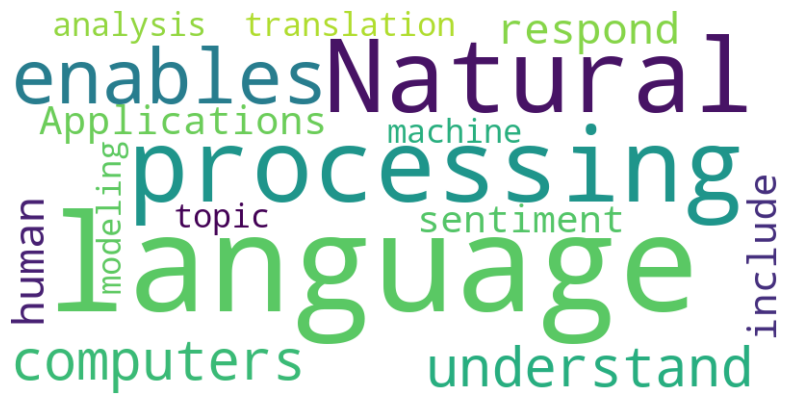

In [31]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt


wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()